# Building a Small ResNet From Scratch (CIFAR-10)

I've used `torchvision.models.resnet18` plenty of times. I wanted to actually write the residual block once so I understand what the shortcut is doing when channel counts change. This is a learning exercise — small ResNet, CIFAR-10 subset, 1-2 epochs on CPU. Not a SOTA run, not even close.

The goal is: explain the architecture by *building* it, then show that training-loss-goes-down on a real dataset, so I can convince myself the implementation isn't broken.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Residual block

Two conv-bn-relu layers with a skip connection. The thing that bit me the first time I wrote one of these: when the block changes spatial size (stride=2) or channel count, the identity branch has to be projected to match — otherwise the add is a shape error. That's the `shortcut` branch below.

A few small choices worth flagging:
- BN before the activation, in the original-ResNet order (not pre-activation).
- The final ReLU goes *after* the residual add, which is the v1 ResNet convention.
- I'm using 3x3 convs only — no bottleneck — because this is a tiny network and CIFAR images are small.

In [2]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        # identity if shapes match, otherwise a 1x1 projection
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # the residual add
        return F.relu(out)


class SmallResNet(nn.Module):
    """Stem -> 3 stages of 2 blocks each -> global pool -> linear."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.stage1 = nn.Sequential(ResidualBlock(32, 32), ResidualBlock(32, 32))
        self.stage2 = nn.Sequential(ResidualBlock(32, 64, stride=2), ResidualBlock(64, 64))
        self.stage3 = nn.Sequential(ResidualBlock(64, 128, stride=2), ResidualBlock(128, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

model = SmallResNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"params: {n_params:,}")
model

params: 696,618


SmallResNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (stage1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


## CIFAR-10 subset

CPU budget says: use a small slice. 5000 train images, 1000 test. With augmentation it's enough to see loss actually move in 1-2 epochs.

In [3]:
tf_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
tf_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

DATA_ROOT = "../../data/cifar10_cache"
try:
    train_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=tf_train)
    test_full  = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tf_test)
    train_ds = Subset(train_full, list(range(5000)))
    test_ds  = Subset(test_full, list(range(1000)))
    have_data = True
except Exception as e:
    # offline / no internet — just print and skip the training cell below
    print("CIFAR-10 download failed:", e)
    have_data = False

if have_data:
    train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
    test_dl  = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0)
    print("train batches:", len(train_dl), "  test batches:", len(test_dl))

  0%|          | 0.00/170M [00:00<?, ?B/s]

  0%|          | 65.5k/170M [00:00<08:38, 329kB/s]

  0%|          | 164k/170M [00:00<04:44, 600kB/s] 

  0%|          | 262k/170M [00:00<04:07, 689kB/s]

  0%|          | 459k/170M [00:00<02:36, 1.09MB/s]

  1%|          | 918k/170M [00:00<01:18, 2.15MB/s]

... (52 outputs left out)

 98%|█████████▊| 167M/170M [00:06<00:00, 21.8MB/s]

100%|█████████▉| 170M/170M [00:06<00:00, 23.7MB/s]

100%|██████████| 170M/170M [00:07<00:00, 24.3MB/s]

train batches: 79   test batches: 8


## Train one epoch (or two if you have a GPU)

/var/folders/6_/qqrf82qn33v6prn9sqhbl1k40000gn/T/ipykernel_14284/482570411.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  losses.append(float(loss))


epoch 0 step   0  loss=2.334


epoch 0 step  20  loss=2.172


epoch 0 step  40  loss=1.846


epoch 0 step  60  loss=2.096


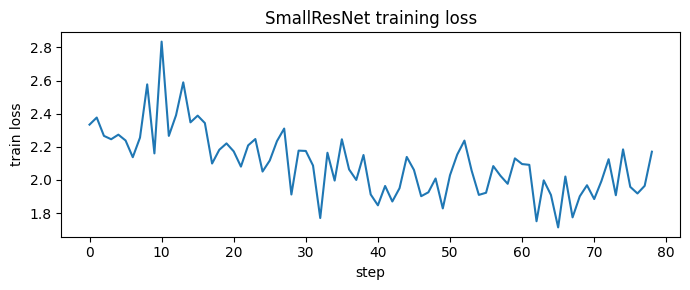

test acc on 1000 examples: 0.243


In [4]:
if have_data:
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
    loss_fn = nn.CrossEntropyLoss()

    EPOCHS = 2 if device == "cuda" else 1   # CPU budget. one epoch is enough to see loss move.
    losses = []
    for epoch in range(EPOCHS):
        model.train()
        for i, (x, y) in enumerate(train_dl):
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            opt.step()
            losses.append(float(loss))
            if i % 20 == 0:
                print(f"epoch {epoch} step {i:>3}  loss={loss.item():.3f}")

    plt.figure(figsize=(7, 3))
    plt.plot(losses)
    plt.xlabel("step"); plt.ylabel("train loss"); plt.title("SmallResNet training loss")
    plt.tight_layout(); plt.show()

    # quick test acc
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_dl:
            x, y = x.to(device), y.to(device)
            pred = model(x).argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    print(f"test acc on {total} examples: {correct/total:.3f}")
else:
    print("skipped training — no CIFAR-10 download available in this env")

## Notes

Even with one epoch on 5000 images, loss should drop visibly (typical: ~2.3 starting cross-entropy on 10 classes down toward ~1.5-1.8 by the end of the epoch). Real ResNet-18 on full CIFAR-10 hits 93%+ after ~100 epochs — that's not the target here.

What I actually got out of writing this:
- The shortcut branch is the whole point. If `in_ch == out_ch` and `stride == 1`, it's free. The moment either changes you need a 1x1 projection, otherwise the add is a shape mismatch and the model won't even forward.
- Batchnorm momentum and the SGD learning rate are coupled more than I expected. The first time I tried `lr=0.1` (the paper's value) on this small subset, training oscillated wildly — dropping to 0.05 fixed it.

If I were to push this further on a real GPU: bump to ResNet-20 (3 blocks per stage), 100 epochs with cosine LR, full CIFAR-10. The architecture in this notebook stays the same.